In [4]:
import gym
import gym_bandits
import numpy as np


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [5]:
env=gym.make('MultiarmedBandits-v0')

In [6]:
print(env.observation_space)

Discrete(1)


In [7]:
print(env.action_space)

Discrete(10)


In [8]:
n_arms =env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards =[]
action_history = []



In [10]:
for episode in range(num_episodes):
    env.reset()

    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)

    observation, reward, done, info = env.step(action)

    counts[action] += 1
    reward_sums[action] += reward
    q_values[action] = reward_sums[action] / counts[action]

    all_rewards.append(reward)
    action_history.append(action)


env.close()

print("Estimated q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all episodes:", round(np.mean(all_rewards), 2))

Estimated q-values for each arm: [-0.14 -0.03 -0.17 -0.2  -0.06  0.07 -0.24 -0.91 -0.14 -1.01]
Number of times each arm was selected: [  3  14  16  24 185 205  14   6  27   6]
Average reward over all episodes: -0.05


/tmp/ipykernel_7137/2710475548.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  reward_sums[action] += reward


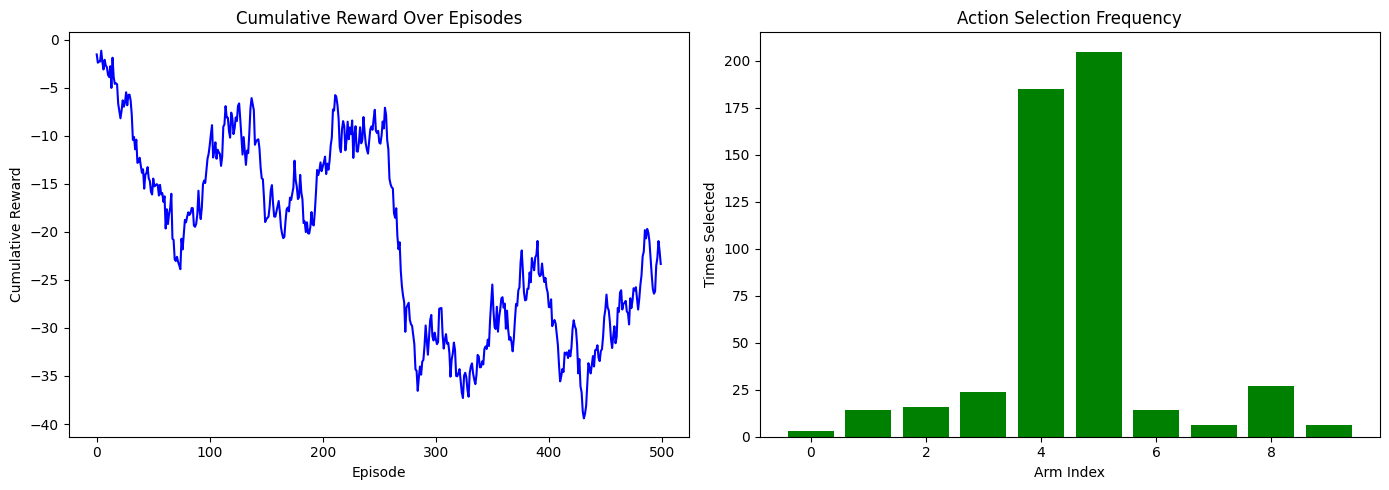

In [16]:
import matplotlib.pyplot as plt

plt. figure(figsize=(14, 5))

plt.subplot (1, 2, 1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot (1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()